<a href="https://colab.research.google.com/github/Bvsrkrishna/Data-Analyst-Projects/blob/main/EDA2_Hotel_Harmony_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hotel Harmony: Data Insights for Optimized Operations
**Company:** Elite Hotels International  |  **Dataset:** Hotel Booking Demand (119,390 bookings, City Hotel & Resort Hotel, 2015–2017)

**How to run in Google Colab:** `Runtime → Run all`. When the data-loading cell asks, upload `hotel_bookings.csv`.

**Notebook structure**
1. Setup & data loading
2. Data cleaning & preprocessing
3. Metric development (KPIs)
4. Basic questions (10, Q1–Q10)
5. Medium questions (10, Q11–Q20)
6. Advanced questions (5, Q21–Q25)
7. Final conclusion, recommendations & further investigation
8. Additional resources

## 1️ Setup & Data Loading

In [ ]:
import warnings, os
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score

sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.titlesize'] = 13
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')

In [ ]:
# ---- Load data (Colab: upload the CSV when prompted; local: place it next to the notebook) ----
if not os.path.exists('hotel bookings.csv'):
    try:
        from google.colab import files
        print('Please upload hotel bookings.csv')
        files.upload()
    except ImportError:
        raise FileNotFoundError('hotel bookings.csv not found in the working directory')

df_raw = pd.read_csv('hotel bookings.csv')
print('Shape:', df_raw.shape)
df_raw.head()

Shape: (119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.000,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.000,0,0,Check-Out,7/1/2015
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.000,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.000,0,0,Check-Out,7/1/2015
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.000,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.000,0,0,Check-Out,7/2/2015
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.000,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.000,NaN,0,Transient,75.000,0,0,Check-Out,7/2/2015
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.000,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.000,NaN,0,Transient,98.000,0,1,Check-Out,7/3/2015


In [ ]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [ ]:
df_raw.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
hotel,119390,2,City Hotel,79330,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_canceled,"119,390.000",NaN,NaN,NaN,0.370,0.483,0.000,0.000,0.000,1.000,1.000
lead_time,"119,390.000",NaN,NaN,NaN,104.011,106.863,0.000,18.000,69.000,160.000,737.000
arrival_date_year,"119,390.000",NaN,NaN,NaN,"2,016.157",0.707,"2,015.000","2,016.000","2,016.000","2,017.000","2,017.000"
arrival_date_month,119390,12,August,13877,NaN,NaN,NaN,NaN,NaN,NaN,NaN
arrival_date_week_number,"119,390.000",NaN,NaN,NaN,27.165,13.605,1.000,16.000,28.000,38.000,53.000
arrival_date_day_of_month,"119,390.000",NaN,NaN,NaN,15.798,8.781,1.000,8.000,16.000,23.000,31.000
stays_in_weekend_nights,"119,390.000",NaN,NaN,NaN,0.928,0.999,0.000,0.000,1.000,2.000,19.000
stays_in_week_nights,"119,390.000",NaN,NaN,NaN,2.500,1.908,0.000,1.000,2.000,3.000,50.000
adults,"119,390.000",NaN,NaN,NaN,1.856,0.579,0.000,2.000,2.000,2.000,55.000


## 2️ Data Cleaning & Preprocessing
Steps required by the brief: handle missing values (`agent`, `company`, `children`), convert dates, check duplicates. I also check for invalid values.

### 2.1 Missing values

In [ ]:
missing = df_raw.isna().sum()
missing = missing[missing > 0].to_frame('missing')
missing['pct'] = missing['missing'] / len(df_raw) * 100
missing

,missing,pct
children,4,0.003
country,488,0.409
agent,16340,13.686
company,112593,94.307


**Treatment (with reasoning)**

| Column | Missing | Treatment | Why |
|---|---|---|---|
| `children` | 4 | fill with **0** | Tiny number; no children recorded means none |
| `country` | 488 | fill with **'Unknown'** | Keep the rows; country is categorical |
| `agent` | ~13.7% | fill with **0** (= "no agent") + keep a flag | Missing means the booking was **not** made through an agent, so it is information, not an error |
| `company` | ~94.3% | fill with **0** (= "no company") | Same logic: missing means no company booked it. Column is too sparse to use as a predictor |

In [ ]:
df = df_raw.copy()

# Keep an explicit flag BEFORE filling (needed for 'bookings made through travel agents')
df['booked_via_agent'] = df['agent'].notna().astype(int)
df['booked_via_company'] = df['company'].notna().astype(int)

df['children'] = df['children'].fillna(0).astype(int)
df['country']  = df['country'].fillna('Unknown')
df['agent']    = df['agent'].fillna(0).astype(int)
df['company']  = df['company'].fillna(0).astype(int)

print('Remaining missing values:', int(df.isna().sum().sum()))

Remaining missing values: 0


### 2.2 Date conversion

In [ ]:
month_order = ['January','February','March','April','May','June','July','August','September','October','November','December']
month_num = {m: i+1 for i, m in enumerate(month_order)}

df['arrival_date'] = pd.to_datetime(dict(year=df['arrival_date_year'],
                                         month=df['arrival_date_month'].map(month_num),
                                         day=df['arrival_date_day_of_month']))
df['reservation_status_date'] = pd.to_datetime(df['reservation_status_date'], format='%m/%d/%Y')
df['arrival_date_month'] = pd.Categorical(df['arrival_date_month'], categories=month_order, ordered=True)

print(df[['arrival_date','reservation_status_date']].dtypes)
print('Arrival date range:', df['arrival_date'].min().date(), 'to', df['arrival_date'].max().date())

arrival_date               datetime64[ns]
reservation_status_date    datetime64[ns]
dtype: object
Arrival date range: 2015-07-01 to 2017-08-31


### 2.3 Duplicates

In [ ]:
n_dup = df_raw.duplicated().sum()
print(f'Fully identical rows: {n_dup:,} ({n_dup/len(df_raw):.1%})')

Fully identical rows: 31,994 (26.8%)


The dataset has **no booking ID**, so identical rows may be genuinely different guests who made the same kind of booking (for example, a family travelling together, or a travel agent block-booking). We therefore **keep all rows as the primary analysis** and run a **robustness check on a de-duplicated copy** (section 2.6) to show the headline KPIs barely change.

### 2.4 Invalid / extreme values

In [ ]:
print('Negative ADR rows        :', (df['adr'] < 0).sum())
print('ADR > 1000 rows (max=%.0f):' % df['adr'].max(), (df['adr'] > 1000).sum())
print('Zero-ADR rows            :', (df['adr'] == 0).sum(), '(mostly complimentary / Complementary segment)')
print('Bookings with 0 guests   :', ((df['adults'] + df['children'] + df['babies']) == 0).sum())
print('Bookings with 0 nights   :', ((df['stays_in_week_nights'] + df['stays_in_weekend_nights']) == 0).sum())

Negative ADR rows        : 1
ADR > 1000 rows (max=5400): 1
Zero-ADR rows            : 1959 (mostly complimentary / Complementary segment)
Bookings with 0 guests   : 180
Bookings with 0 nights   : 715


In [ ]:
# One negative ADR (data-entry error) and one ADR of 5,400 (extreme outlier, ~50x the mean) distort every price analysis.
before = len(df)
df = df[(df['adr'] >= 0) & (df['adr'] < 1000)].copy()
print(f'Removed {before - len(df)} rows with impossible/extreme ADR. Rows now: {len(df):,}')

Removed 2 rows with impossible/extreme ADR. Rows now: 119,388


### 2.5 Feature engineering

In [ ]:
df['total_nights'] = df['stays_in_week_nights'] + df['stays_in_weekend_nights']
df['total_guests'] = df['adults'] + df['children'] + df['babies']
df['revenue']      = df['adr'] * df['total_nights']          # room revenue of a booking
df['room_changed'] = (df['reserved_room_type'] != df['assigned_room_type']).astype(int)

season_map = {12:'Winter',1:'Winter',2:'Winter',3:'Spring',4:'Spring',5:'Spring',
              6:'Summer',7:'Summer',8:'Summer',9:'Autumn',10:'Autumn',11:'Autumn'}
df['season'] = df['arrival_date'].dt.month.map(season_map)

print('Clean dataset shape:', df.shape)
df.head()

Clean dataset shape: (119388, 40)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,booked_via_agent,booked_via_company,arrival_date,total_nights,total_guests,revenue,room_changed,season
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,0,0,0,Transient,0.000,0,0,Check-Out,2015-07-01,0,0,2015-07-01,0,2,0.000,0,Summer
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,0,0,0,Transient,0.000,0,0,Check-Out,2015-07-01,0,0,2015-07-01,0,2,0.000,0,Summer
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,0,0,0,Transient,75.000,0,0,Check-Out,2015-07-02,0,0,2015-07-01,1,1,75.000,1,Summer
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304,0,0,Transient,75.000,0,0,Check-Out,2015-07-02,1,0,2015-07-01,1,1,75.000,0,Summer
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240,0,0,Transient,98.000,0,1,Check-Out,2015-07-03,1,0,2015-07-01,2,2,196.000,0,Summer


### 2.6 Robustness check: de-duplicated copy

In [ ]:
df_dedup = df.drop_duplicates(subset=df_raw.columns.tolist())
robust = pd.DataFrame({
    'All rows': [len(df), df['lead_time'].mean(), df['is_canceled'].mean()*100, df['adr'].mean()],
    'De-duplicated': [len(df_dedup), df_dedup['lead_time'].mean(), df_dedup['is_canceled'].mean()*100, df_dedup['adr'].mean()]
}, index=['Bookings', 'Avg lead time (days)', 'Cancellation rate (%)', 'Avg ADR'])
robust

,All rows,De-duplicated
Bookings,"119,388.000","87,394.000"
Avg lead time (days),104.011,79.891
Cancellation rate (%),37.041,27.489
Avg ADR,101.788,106.278


> Removing duplicates lowers the headline cancellation rate noticeably (≈37% → ≈27%) and shortens the average lead time, so **absolute levels depend on how duplicates are treated**. The **rankings and conclusions hold** (e.g. City Hotel still cancels more than Resort: ≈30% vs ≈23%). The main analysis uses all rows; this check is shown for transparency.

## 3️ Metric Development (KPIs)
The five metrics defined in the brief, computed overall and per hotel.

In [ ]:
def kpis(d):
    nc = d[d['is_canceled'] == 0]
    return pd.Series({
        'Bookings': len(d),
        'Avg booking lead time (days)': d['lead_time'].mean(),
        'Cancellation rate (%)': d['is_canceled'].mean() * 100,
        'Avg nights stayed per booking (non-cancelled)': nc['total_nights'].mean(),
        'Avg special requests per booking': d['total_of_special_requests'].mean(),
        'Avg ADR (non-cancelled)': nc['adr'].mean(),
        'Total room revenue (non-cancelled)': nc['revenue'].sum(),
    })

kpi_table = pd.concat([kpis(df).rename('Overall'),
                       df.groupby('hotel').apply(kpis).T], axis=1)
kpi_table.style.format('{:,.2f}')

,Overall,City Hotel,Resort Hotel
Bookings,"119,388.00","79,329.00","40,059.00"
Avg booking lead time (days),104.01,109.74,92.67
Cancellation rate (%),37.04,41.73,27.76
Avg nights stayed per booking (non-cancelled),3.39,2.92,4.14
Avg special requests per booking,0.57,0.55,0.62
Avg ADR (non-cancelled),99.99,105.75,90.79
Total room revenue (non-cancelled),"25,996,324.21","14,394,410.18","11,601,914.03"


> **Note on "Occupancy Rate":** the dataset has no room-inventory counts, so a true occupancy % cannot be computed. As the brief defines, we use *average nights stayed per booking* as the proxy.

## 4️ Basic Level Questions

### Q1. What is the average lead time for bookings?

Average lead time: 104.0 days  (median = 69 days)


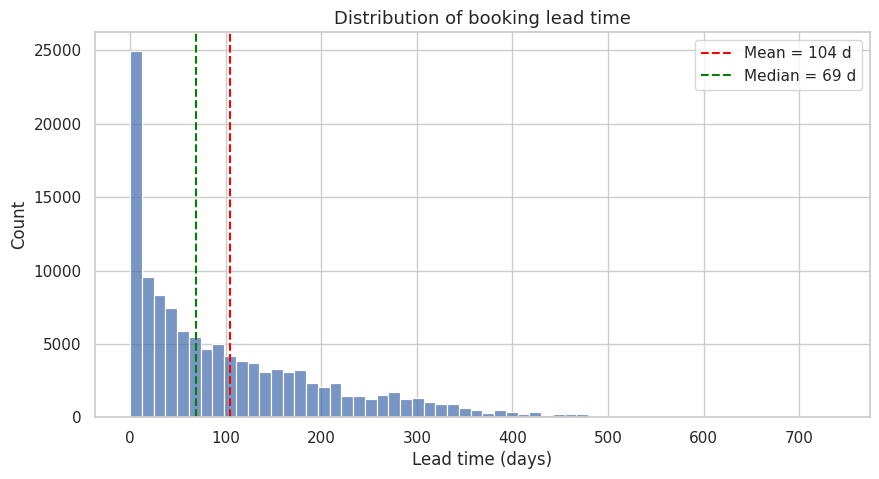

In [ ]:
avg_lead = df['lead_time'].mean()
print(f'Average lead time: {avg_lead:.1f} days  (median = {df["lead_time"].median():.0f} days)')

fig, ax = plt.subplots()
sns.histplot(df['lead_time'], bins=60, ax=ax)
ax.axvline(avg_lead, color='red', ls='--', label=f'Mean = {avg_lead:.0f} d')
ax.axvline(df['lead_time'].median(), color='green', ls='--', label=f'Median = {df["lead_time"].median():.0f} d')
ax.set_title('Distribution of booking lead time'); ax.set_xlabel('Lead time (days)'); ax.legend()
plt.show()

**Insight:** Guests book on average ~**104 days** ahead, but the distribution is heavily right-skewed (median ≈ 69 days): many last-minute bookings plus a long tail of very early ones.
**Business impact:** Run campaigns ~3–4 months before peak season, and keep a separate last-minute (<30 days) strategy for the large group of late bookers.

### Q2. What is the distribution of bookings by hotel type?

              Bookings  Share (%)
hotel                            
City Hotel       79329     66.446
Resort Hotel     40059     33.554


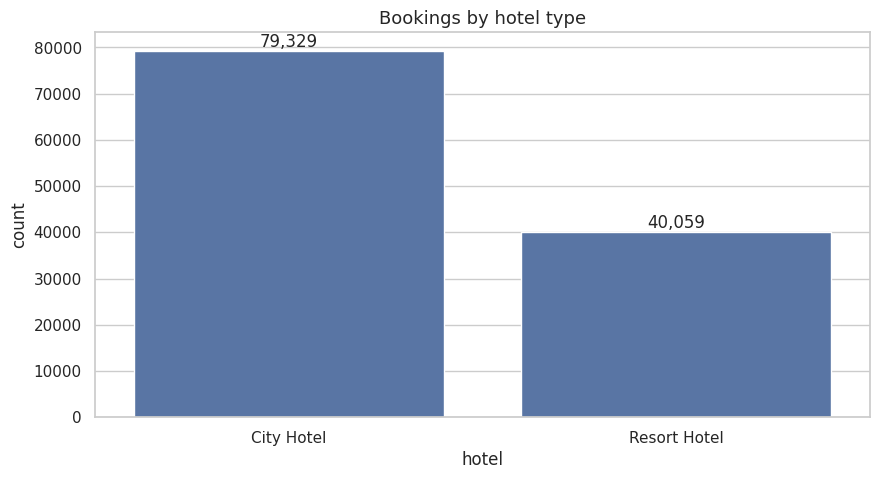

In [ ]:
hotel_counts = df['hotel'].value_counts()
print(pd.DataFrame({'Bookings': hotel_counts, 'Share (%)': hotel_counts / len(df) * 100}))

ax = sns.countplot(data=df, x='hotel', order=hotel_counts.index)
for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}', (p.get_x() + p.get_width()/2, p.get_height()),
                ha='center', va='bottom')
ax.set_title('Bookings by hotel type'); plt.show()

**Insight:** City Hotel receives roughly **twice** the bookings of Resort Hotel (~66% vs ~34%).
**Business impact:** City Hotel is the volume driver, so marketing spend and staffing there have the largest absolute effect; Resort Hotel needs targeted demand generation.

### Q3. How many bookings were canceled?

Cancelled bookings: 44,223 of 119,388  ->  37.0%


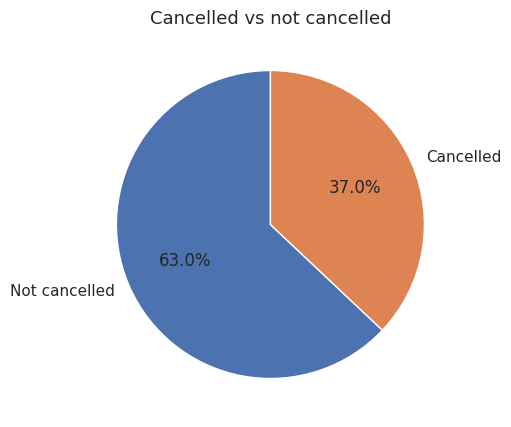

In [ ]:
n_cancel = int(df['is_canceled'].sum())
print(f'Cancelled bookings: {n_cancel:,} of {len(df):,}  ->  {n_cancel/len(df):.1%}')

df['is_canceled'].map({0:'Not cancelled',1:'Cancelled'}).value_counts().plot.pie(
    autopct='%1.1f%%', startangle=90, ylabel='', title='Cancelled vs not cancelled')
plt.show()

**Insight:** Almost **4 in 10** bookings (44,223 after cleaning; 44,224 in the raw file, before removing one extreme-ADR row) are cancelled.
**Business impact:** This is a major revenue-uncertainty risk. It justifies deposit policies, controlled overbooking and re-selling cancelled inventory.

### Q4. What is the most common arrival month for bookings?

Most common arrival month: August (13,877 bookings)


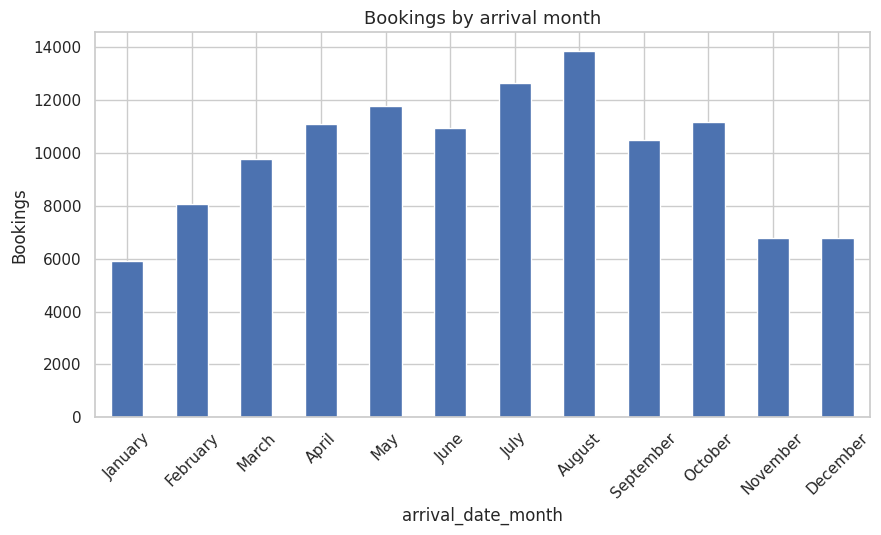

In [ ]:
month_counts = df['arrival_date_month'].value_counts().reindex(month_order)
print('Most common arrival month:', month_counts.idxmax(), f'({month_counts.max():,} bookings)')

ax = month_counts.plot.bar(color=sns.color_palette('deep')[0])
ax.set_title('Bookings by arrival month'); ax.set_ylabel('Bookings'); plt.xticks(rotation=45)
plt.show()

**Insight:** **August** is the busiest arrival month, with July close behind; December–January are the quietest.
**Business impact:** Staff up, stock up and price up for July–August; use off-peak promotions (Nov–Feb) to fill rooms.

### Q5. What is the average number of special requests per booking?

Average special requests per booking: 0.57
Bookings with no request: 58.9%


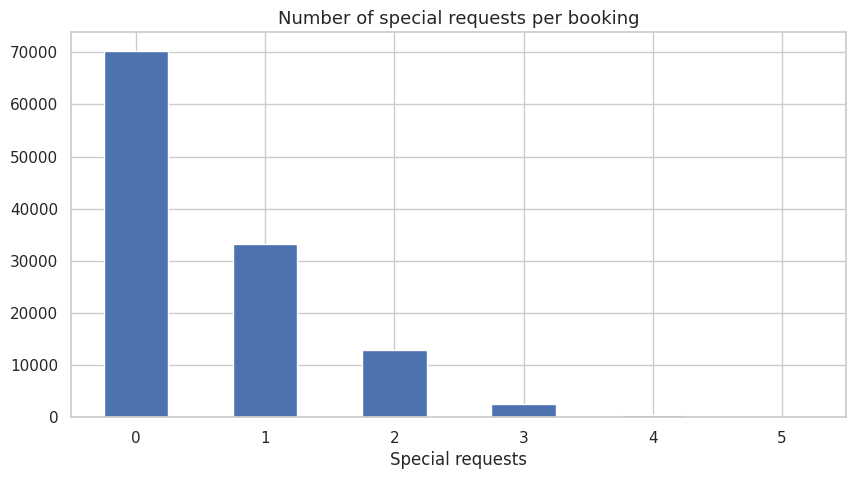

In [ ]:
print(f"Average special requests per booking: {df['total_of_special_requests'].mean():.2f}")
print(f"Bookings with no request: {(df['total_of_special_requests']==0).mean():.1%}")
ax = df['total_of_special_requests'].value_counts().sort_index().plot.bar()
ax.set_title('Number of special requests per booking'); ax.set_xlabel('Special requests'); plt.xticks(rotation=0)
plt.show()

**Insight:** On average only ~**0.57** requests per booking, and the majority of bookings make none.
**Business impact:** Service demand is light but concentrated in a minority of guests; identify those guests early (pre-arrival email) to deliver personalised service.

### Q6. Which country has the highest number of bookings?

country
PRT    48589
GBR    12128
FRA    10415
ESP     8568
DEU     7287
ITA     3766
IRL     3375
BEL     2342
BRA     2224
NLD     2104
Name: count, dtype: int64

Top country: PRT  (40.7% of all bookings)


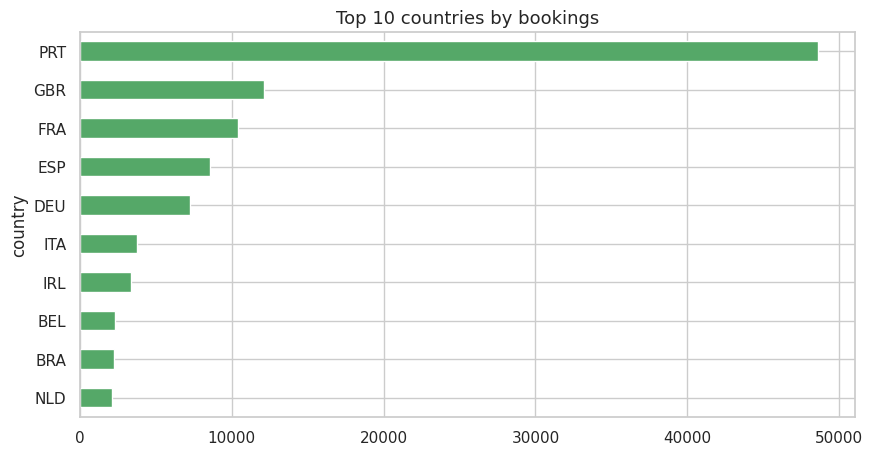

In [ ]:
top_countries = df['country'].value_counts().head(10)
print(top_countries)
print(f"\nTop country: {top_countries.index[0]}  ({top_countries.iloc[0]/len(df):.1%} of all bookings)")
top_countries.sort_values().plot.barh(title='Top 10 countries by bookings', color=sns.color_palette('deep')[2])
plt.show()

**Insight:** **Portugal (PRT)** dominates (~41%), followed by Great Britain, France, Spain and Germany. The hotels are in Portugal.
**Business impact:** Focus on domestic and Western-European source markets; localise websites and offers for PT, UK, FR, ES, DE.

### Q7. What is the average daily rate (ADR) for each hotel type?

                mean  median    std
hotel                              
City Hotel   105.240  99.900 39.340
Resort Hotel  94.960  75.000 61.440


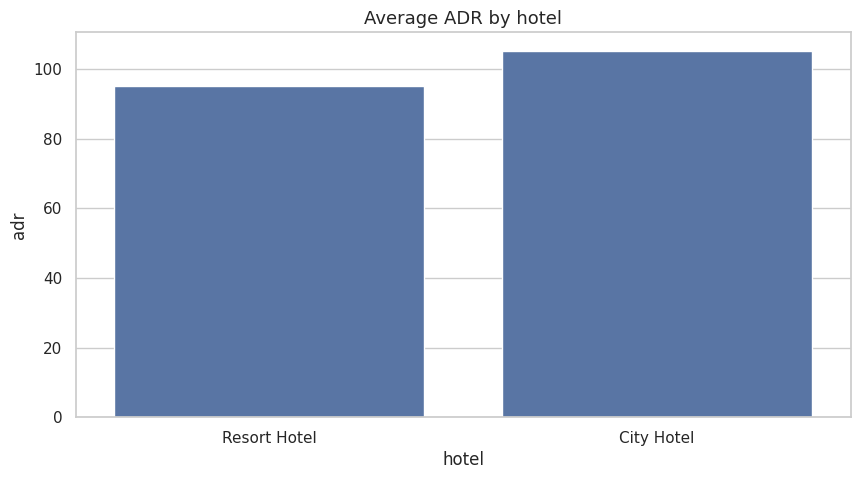

In [ ]:
adr_hotel = df.groupby('hotel')['adr'].agg(['mean','median','std']).round(2)
print(adr_hotel)
sns.barplot(data=df, x='hotel', y='adr', errorbar=None)
plt.title('Average ADR by hotel'); plt.show()

**Insight:** City Hotel earns a higher mean ADR (~€105) than Resort Hotel (~€95), but Resort rates swing much more (std ≈ €61 vs €39; see also the monthly chart in Q16).
**Business impact:** Different pricing strategies are needed: stable year-round pricing for City, strongly season-based dynamic pricing for Resort.

### Q8. What percentage of guests required car parking spaces?

In [ ]:
pct_park = (df['required_car_parking_spaces'] > 0).mean() * 100
print(f'Bookings requiring parking: {pct_park:.2f}%')
print(df.groupby('hotel')['required_car_parking_spaces'].apply(lambda s: (s > 0).mean() * 100).round(2).to_string())

Bookings requiring parking: 6.21%
hotel
City Hotel      2.430
Resort Hotel   13.700


**Insight:** Only ~**6%** of bookings need a parking space, and the share is far higher at the Resort Hotel than at the City Hotel.
**Business impact:** Parking capacity matters mostly for Resort; City Hotel can partner with public car parks instead of building capacity.

### Q9. What is the average stay duration in week nights and weekend nights?

In [ ]:
print(f"Avg week nights   : {df['stays_in_week_nights'].mean():.2f}")
print(f"Avg weekend nights: {df['stays_in_weekend_nights'].mean():.2f}")
print(f"Avg total nights  : {df['total_nights'].mean():.2f}")
print(df.groupby('hotel')[['stays_in_week_nights','stays_in_weekend_nights','total_nights']].mean().round(2))

Avg week nights   : 2.50
Avg weekend nights: 0.93
Avg total nights  : 3.43
              stays_in_week_nights  stays_in_weekend_nights  total_nights
hotel                                                                    
City Hotel                   2.180                    0.800         2.980
Resort Hotel                 3.130                    1.190         4.320


**Insight:** An average stay is ~**3.4 nights** (≈2.5 week nights + ≈0.9 weekend nights). Resort guests stay longer than City guests.
**Business impact:** Offer 3–4 night packages; upsell weekend add-ons at City; length-of-stay discounts at Resort.

### Q10. How many bookings were made through travel agents?

Bookings via a travel agent: 103,048  (86.3%)
Number of distinct agents  : 333


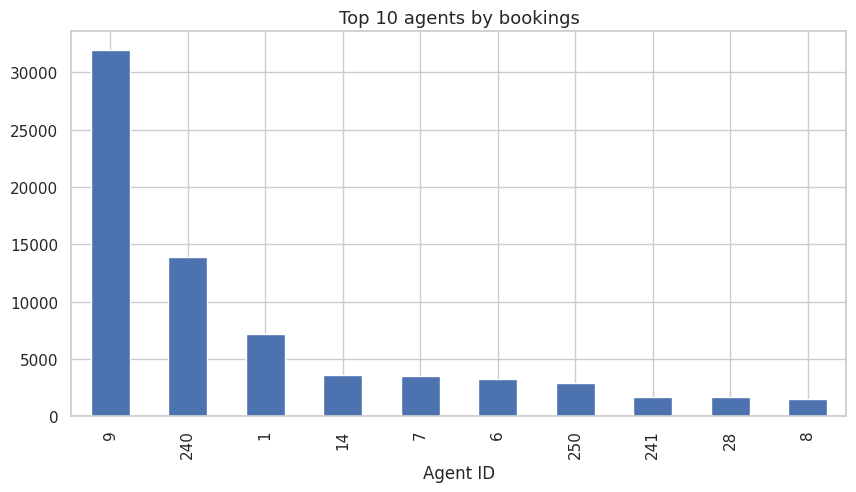

In [ ]:
n_agent = int(df['booked_via_agent'].sum())
print(f'Bookings via a travel agent: {n_agent:,}  ({n_agent/len(df):.1%})')
print(f'Number of distinct agents  : {df.loc[df.booked_via_agent==1, "agent"].nunique()}')
top_agents = df.loc[df.booked_via_agent==1, 'agent'].value_counts().head(10)
top_agents.index = top_agents.index.astype(str)
top_agents.plot.bar(title='Top 10 agents by bookings'); plt.xlabel('Agent ID'); plt.show()

**Insight:** About **86%** of bookings come through a travel agent, and a handful of agents (e.g. agent 9) account for a large share.
**Business impact:** Agents are critical partners. Negotiate preferred-partner terms with top agents, but diversify to reduce dependency.

## 5️ Medium Level Questions

### Q11. What is the cancellation rate for each hotel type?

hotel
City Hotel     41.730
Resort Hotel   27.760


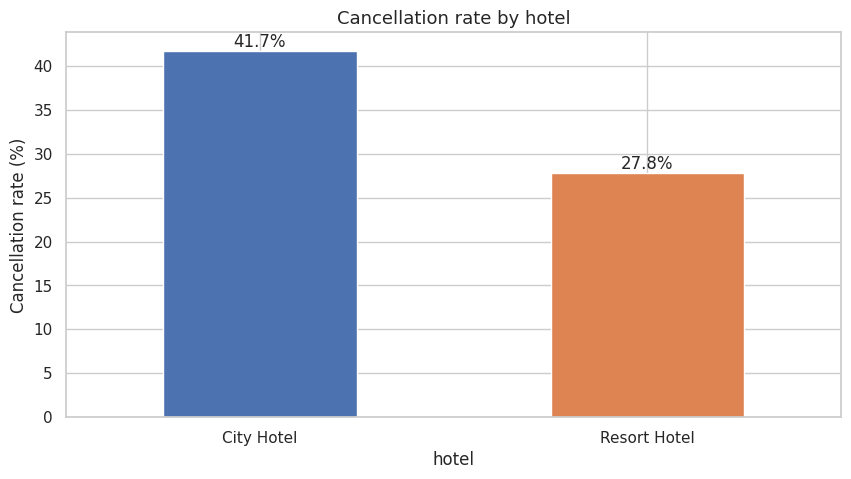

In [ ]:
cr_hotel = df.groupby('hotel')['is_canceled'].mean() * 100
print(cr_hotel.round(2).to_string())
ax = cr_hotel.plot.bar(color=['#4c72b0','#dd8452'])
for p in ax.patches: ax.annotate(f'{p.get_height():.1f}%', (p.get_x()+p.get_width()/2, p.get_height()), ha='center', va='bottom')
ax.set_ylabel('Cancellation rate (%)'); ax.set_title('Cancellation rate by hotel'); plt.xticks(rotation=0); plt.show()

**Insight:** City Hotel cancels at ~**42%** vs ~**28%** at the Resort. A 14-point gap.
**Business impact:** City Hotel needs stricter policies (deposits/non-refundable rates) and a carefully managed overbooking buffer.

### Q12. What is the average ADR per market segment?

                  mean  median  count
market_segment                       
Online TA      117.200 109.800  56477
Direct         115.450 105.000  12606
Aviation       100.140  95.000    237
Offline TA/TO   87.140  85.500  24218
Groups          79.480  70.000  19810
Corporate       69.360  65.000   5295
Undefined       15.000  15.000      2
Complementary    2.890   0.000    743


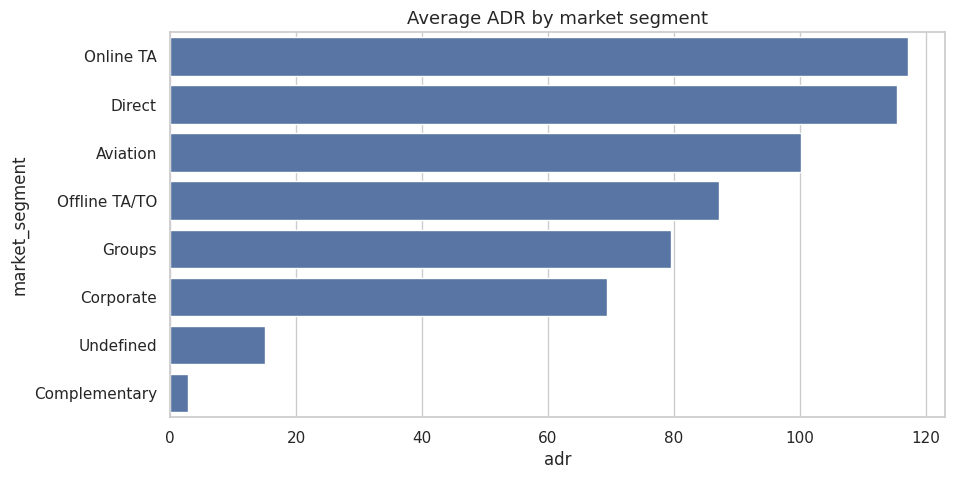

In [ ]:
adr_seg = df.groupby('market_segment')['adr'].agg(['mean','median','count']).sort_values('mean', ascending=False).round(2)
print(adr_seg)
sns.barplot(data=df, y='market_segment', x='adr', order=adr_seg.index, errorbar=None)
plt.title('Average ADR by market segment'); plt.show()

**Insight:** **Online TA** and **Direct** have the highest ADR (~€115–117); Corporate and Groups are discounted; Complementary is almost free by definition.
**Business impact:** Shift mix towards Direct (no commission, high ADR) and grow Online TA, while keeping Groups/Corporate for volume in low season.

### Q13. What is the relationship between lead time and cancellation rate?

Point-biserial correlation (lead_time vs is_canceled): r = 0.293, p = 0


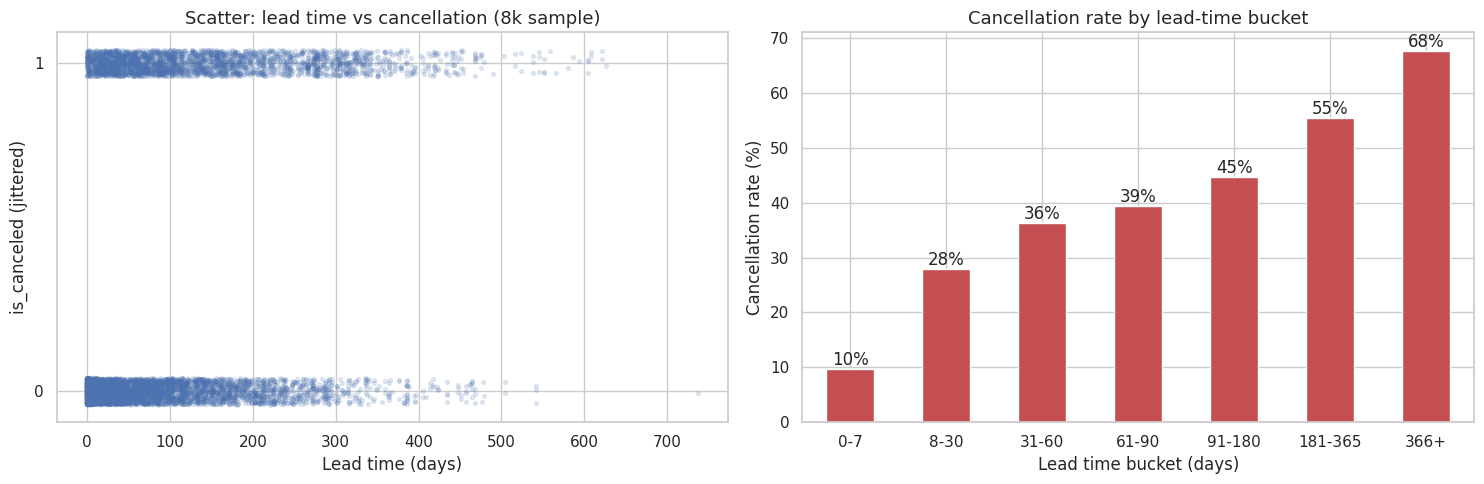

In [ ]:
corr, p = stats.pointbiserialr(df['is_canceled'], df['lead_time'])
print(f'Point-biserial correlation (lead_time vs is_canceled): r = {corr:.3f}, p = {p:.2g}')

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
# (a) The scatter plot suggested in the brief (jittered, sampled so points are visible)
samp = df.sample(8000, random_state=1)
axes[0].scatter(samp['lead_time'], samp['is_canceled'] + np.random.uniform(-0.04, 0.04, len(samp)), alpha=0.15, s=8)
axes[0].set_yticks([0,1]); axes[0].set_xlabel('Lead time (days)'); axes[0].set_ylabel('is_canceled (jittered)')
axes[0].set_title('Scatter: lead time vs cancellation (8k sample)')

# (b) Much clearer: cancellation RATE per lead-time bucket
bins = [-1, 7, 30, 60, 90, 180, 365, 800]
labels = ['0-7','8-30','31-60','61-90','91-180','181-365','366+']
df['lead_bucket'] = pd.cut(df['lead_time'], bins=bins, labels=labels)
rate = df.groupby('lead_bucket', observed=True)['is_canceled'].mean() * 100
rate.plot.bar(ax=axes[1], color=sns.color_palette('deep')[3])
for p_ in axes[1].patches: axes[1].annotate(f'{p_.get_height():.0f}%', (p_.get_x()+p_.get_width()/2, p_.get_height()), ha='center', va='bottom')
axes[1].set_ylabel('Cancellation rate (%)'); axes[1].set_xlabel('Lead time bucket (days)')
axes[1].set_title('Cancellation rate by lead-time bucket'); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

**Insight:** There is a clear **positive relationship** (r ≈ 0.29): the cancellation rate rises steadily with lead time, from ≈10% for bookings made in the last week, to ≈45% at 3–6 months, to ≈68% for bookings made more than a year ahead. (A raw scatter of a 0/1 variable is hard to read, hence the bucketed rate chart.)
**Business impact:** Require deposits or offer non-refundable discounts on long-lead bookings; send reminder/re-confirmation messages as the arrival date approaches.

### Q14. Which distribution channel has the highest number of bookings?

                      Bookings  Share (%)
distribution_channel                     
TA/TO                    97869     81.980
Direct                   14644     12.270
Corporate                 6677      5.590
GDS                        193      0.160
Undefined                    5      0.000


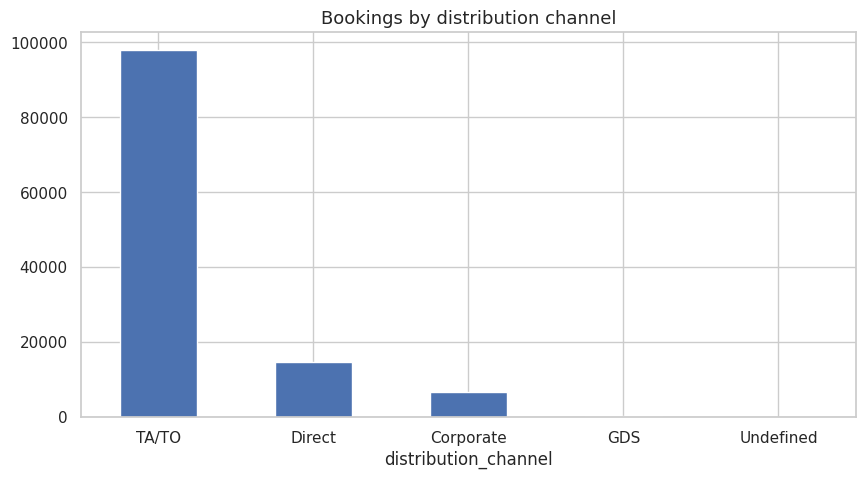

In [ ]:
ch = df['distribution_channel'].value_counts()
print(pd.DataFrame({'Bookings': ch, 'Share (%)': ch / len(df) * 100}).round(2))
ch.plot.bar(title='Bookings by distribution channel'); plt.xticks(rotation=0); plt.show()

**Insight:** **TA/TO** (travel agents / tour operators) is by far the largest channel (~82%); Direct is second.
**Business impact:** Heavy reliance on intermediaries means commission costs. Growing Direct bookings (loyalty perks, best-rate guarantee) would improve margin.

### Q15. What is the average number of previous cancellations by hotel type?

hotel
City Hotel     0.080
Resort Hotel   0.102


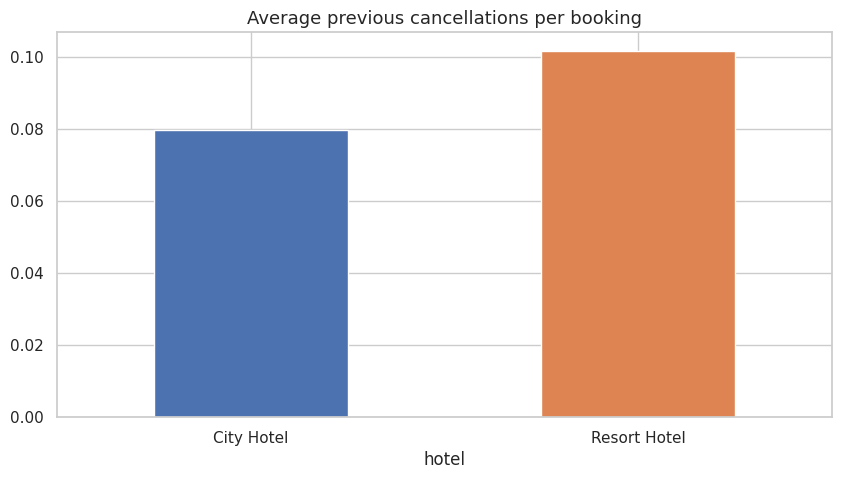

In [ ]:
pc = df.groupby('hotel')['previous_cancellations'].mean()
print(pc.round(4).to_string())
pc.plot.bar(title='Average previous cancellations per booking', color=['#4c72b0','#dd8452']); plt.xticks(rotation=0); plt.show()

**Insight:** Resort Hotel guests have slightly **more** previous cancellations on average (~0.10 vs ~0.08), even though Resort has the *lower* cancellation rate for the current booking. Past behaviour alone is not the whole story.
**Business impact:** Use a guest's cancellation history as one signal in booking-risk scoring, not as the only one.

### Q16. What is the trend of ADR over the years?

arrival_date_year
2015    87.180
2016    98.230
2017   114.640


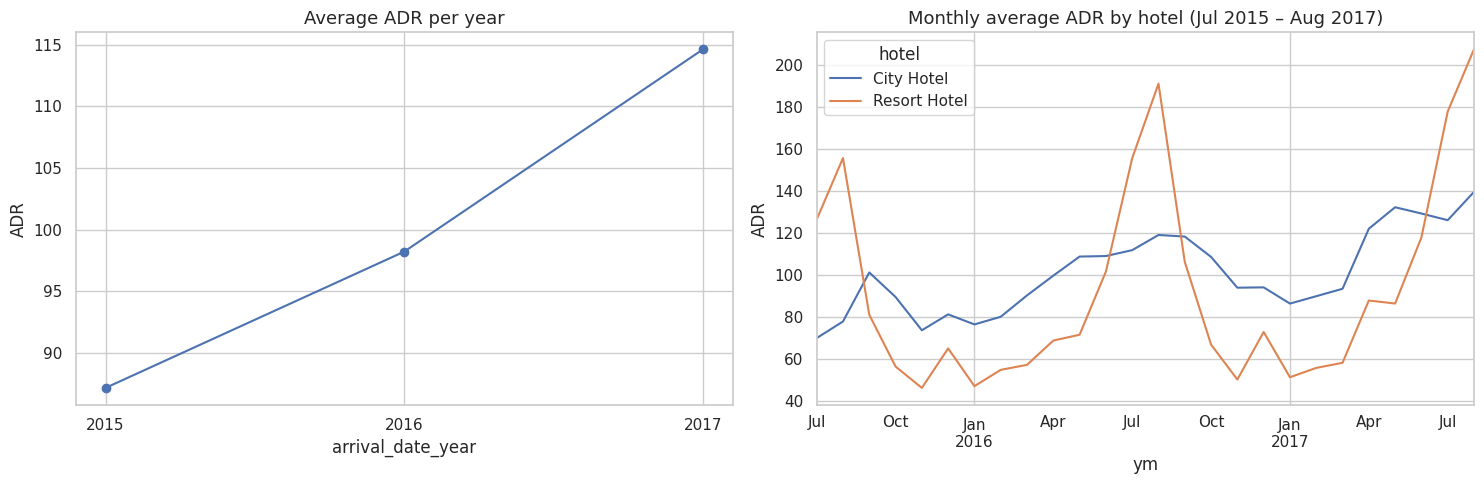

In [ ]:
adr_year = df.groupby('arrival_date_year')['adr'].mean()
print(adr_year.round(2).to_string())

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
adr_year.plot(marker='o', ax=axes[0]); axes[0].set_xticks(adr_year.index)
axes[0].set_title('Average ADR per year'); axes[0].set_ylabel('ADR')

# Monthly timeline (more detail), by hotel
monthly = (df.assign(ym=df['arrival_date'].dt.to_period('M').dt.to_timestamp())
             .groupby(['ym','hotel'])['adr'].mean().unstack())
monthly.plot(ax=axes[1]); axes[1].set_title('Monthly average ADR by hotel (Jul 2015 – Aug 2017)'); axes[1].set_ylabel('ADR')
plt.tight_layout(); plt.show()

**Insight:** ADR rose **every year** (2015 ≈ €87 → 2016 ≈ €98 → 2017 ≈ €115) and shows strong **summer peaks**, especially at the Resort Hotel. *Caveat:* 2015 only covers Jul–Dec and 2017 only Jan–Aug, so part of the yearly rise is a seasonal-mix effect, but the month-by-month chart confirms real price growth.
**Business impact:** Pricing power has been growing; continue dynamic pricing, with the largest premiums in peak months.

### Q17. Which month has the highest revenue?

Highest revenue month (sum of ADR, brief method): August
Highest revenue month (ADR x nights, non-cancelled): August -> 4,917,159


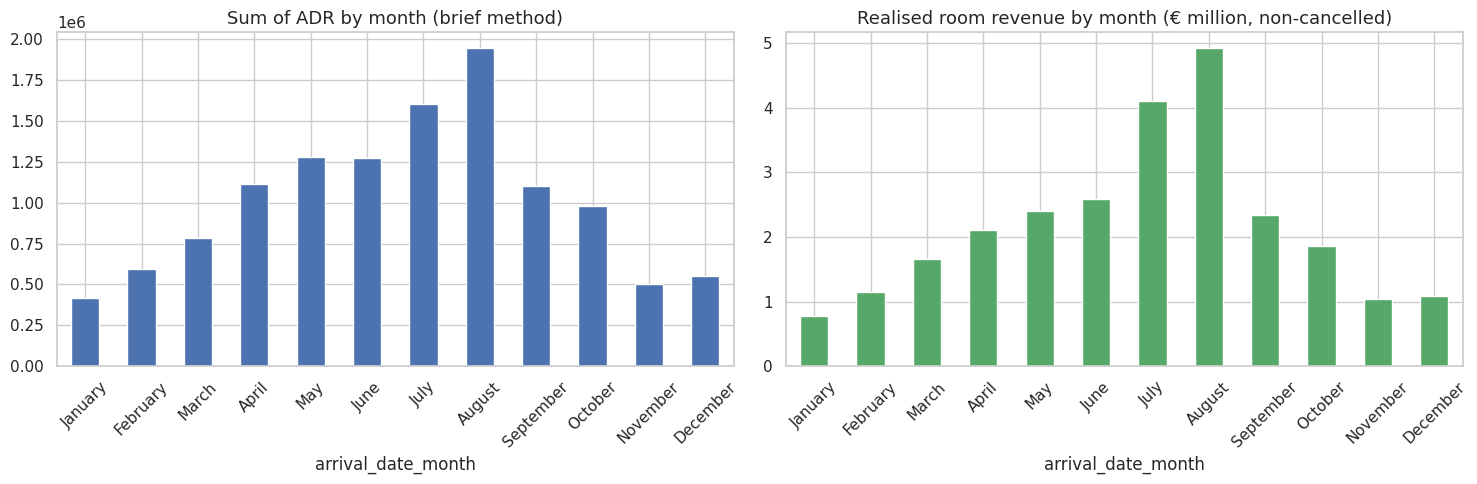

In [ ]:
nc = df[df['is_canceled'] == 0]

# (a) Method suggested in the brief: sum of ADR
rev_adr_sum = df.groupby('arrival_date_month', observed=True)['adr'].sum().reindex(month_order)
# (b) More accurate: realised room revenue = ADR x nights, for stays that were NOT cancelled
rev_true = nc.groupby('arrival_date_month', observed=True)['revenue'].sum().reindex(month_order)

print('Highest revenue month (sum of ADR, brief method):', rev_adr_sum.idxmax())
print('Highest revenue month (ADR x nights, non-cancelled):', rev_true.idxmax(), f'-> {rev_true.max():,.0f}')

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
rev_adr_sum.plot.bar(ax=axes[0], color=sns.color_palette('deep')[0]); axes[0].set_title('Sum of ADR by month (brief method)')
(rev_true/1e6).plot.bar(ax=axes[1], color=sns.color_palette('deep')[2]); axes[1].set_title('Realised room revenue by month (€ million, non-cancelled)')
for a in axes: a.tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()

**Insight:** Both methods agree: **August** is the highest-revenue month, followed by July. Revenue is strongly seasonal.
**Business impact:** Protect peak-month inventory (minimum-stay rules, higher rates) and run demand-building offers in shoulder/off-peak months.

### Q18. What is the impact of special requests on ADR?

Pearson correlation (special requests vs ADR): 0.181
                             mean  count
total_of_special_requests               
0                          94.890  70316
1                         108.460  33226
2                         117.030  12969
3                         123.850   2497
4                         130.570    340
5                         127.750     40


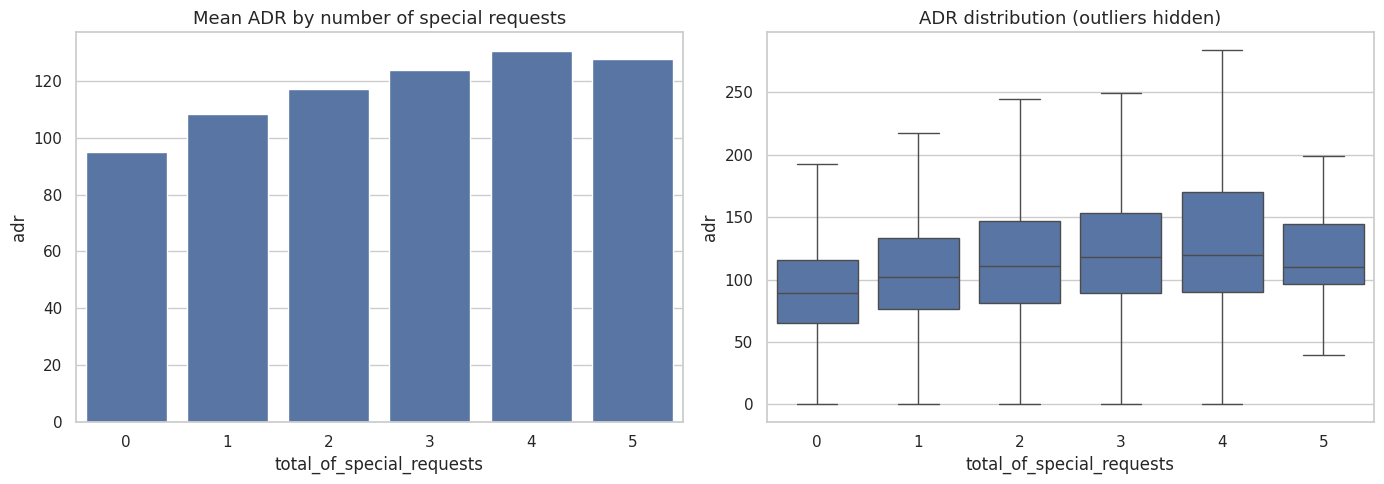

In [ ]:
corr = df[['total_of_special_requests','adr']].corr().iloc[0,1]
print(f'Pearson correlation (special requests vs ADR): {corr:.3f}')
print(df.groupby('total_of_special_requests')['adr'].agg(['mean','count']).round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=df, x='total_of_special_requests', y='adr', errorbar=None, ax=axes[0]); axes[0].set_title('Mean ADR by number of special requests')
sns.boxplot(data=df, x='total_of_special_requests', y='adr', showfliers=False, ax=axes[1]); axes[1].set_title('ADR distribution (outliers hidden)')
plt.tight_layout(); plt.show()

**Insight:** A weak **positive** relationship (r ≈ 0.18): guests who make more requests tend to pay somewhat more. It is a modest effect, not a strong driver of price. Some of it is explained by room type, season and guest composition (see Q22).
**Business impact:** Guests with many requests are slightly higher-value, which is an opportunity for paid add-ons (room upgrades, bed type, high floor, packages).

### Q19. What is the average stay duration for repeated vs new guests?

                   stays_in_week_nights  stays_in_weekend_nights  total_nights
is_repeated_guest                                                             
New guest                         2.530                    0.940         3.480
Repeated guest                    1.480                    0.450         1.920

Share of repeated guests: 3.19%


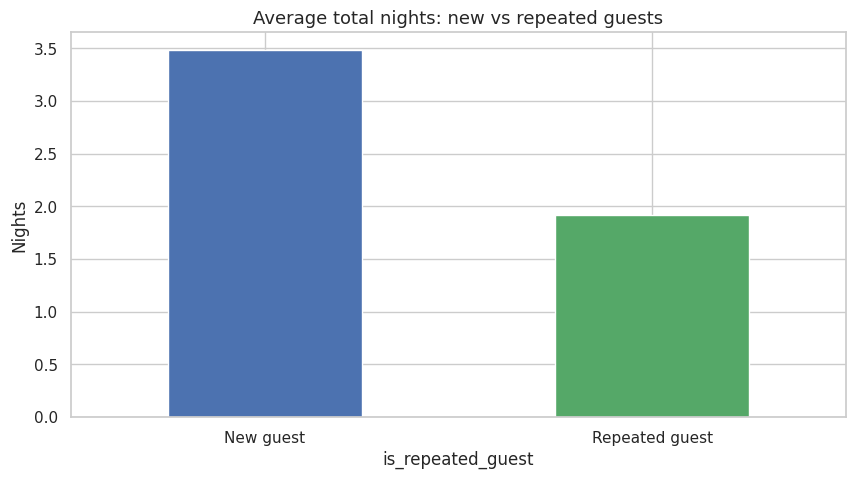

In [ ]:
rep = df.groupby('is_repeated_guest')[['stays_in_week_nights','stays_in_weekend_nights','total_nights']].mean().round(2)
rep.index = rep.index.map({0:'New guest', 1:'Repeated guest'})
print(rep)
print('\nShare of repeated guests: {:.2%}'.format(df['is_repeated_guest'].mean()))
rep['total_nights'].plot.bar(title='Average total nights: new vs repeated guests', color=['#4c72b0','#55a868']); plt.xticks(rotation=0); plt.ylabel('Nights'); plt.show()

**Insight:** Repeated guests stay **shorter** (~1.9 nights vs ~3.5 for new guests) and make up only ~3% of bookings.
**Business impact:** Repeat guests are typically short, convenient trips, and they are rare. A loyalty programme should aim to raise repeat share and encourage longer stays with stay-more-save-more rewards.

### Q20. Which room type has the highest number of bookings?

                    Bookings  Share (%)
reserved_room_type                     
A                      85992     72.030
D                      19201     16.080
E                       6535      5.470
F                       2897      2.430
G                       2094      1.750
B                       1118      0.940
C                        932      0.780
H                        601      0.500
P                         12      0.010
L                          6      0.010


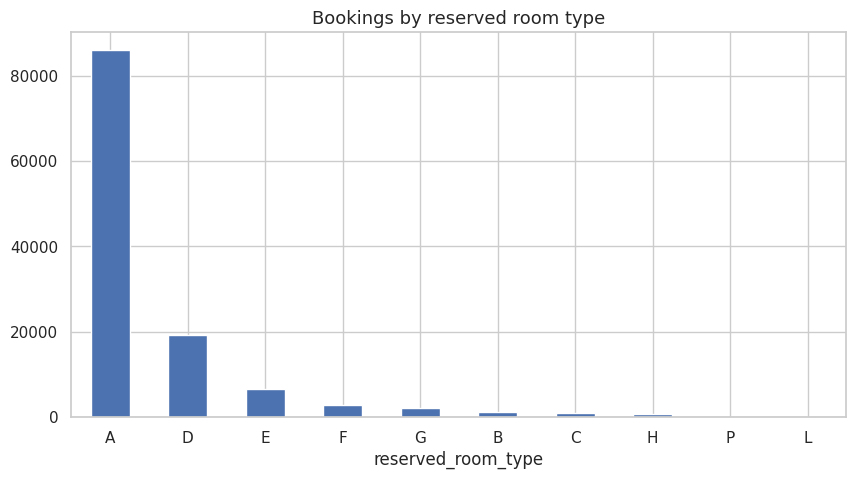


Bookings where assigned room != reserved room: 12.5%


In [ ]:
rt = df['reserved_room_type'].value_counts()
print(pd.DataFrame({'Bookings': rt, 'Share (%)': rt / len(df) * 100}).round(2))
rt.plot.bar(title='Bookings by reserved room type'); plt.xticks(rotation=0); plt.show()
print(f"\nBookings where assigned room != reserved room: {df['room_changed'].mean():.1%}")

**Insight:** **Room type A** accounts for about 72% of bookings; D and E follow far behind.
**Business impact:** Keep A-type inventory the largest and protect it from over-selling. Review pricing/upsell paths for the less-booked premium types. About 1 in 8 guests is assigned a different room than reserved, so manage upgrades/downgrades carefully.

## 6️ Advanced Level Questions

### Q21. What factors significantly impact the cancellation rate? (Logistic regression)
**Approach:** Logistic regression with `is_canceled` as the target. Numeric predictors are standardised so odds ratios are comparable (*OR per +1 standard deviation*); categorical predictors are one-hot encoded. `statsmodels` gives p-values/significance; a `scikit-learn` hold-out test checks predictive performance.

In [ ]:
# Parking is analysed separately: NOT ONE of the guests who required a parking space cancelled (perfect separation),
# which makes a logistic coefficient meaningless (it diverges to -infinity), so it is excluded from the model.
print(df.groupby(df['required_car_parking_spaces'] > 0)['is_canceled'].agg(['mean','sum','size'])
        .rename(index={False:'No parking needed', True:'Parking needed'}, columns={'mean':'cancel_rate','sum':'cancellations','size':'bookings'}))

num_cols = ['lead_time','booking_changes','total_of_special_requests','previous_cancellations',
            'previous_bookings_not_canceled','is_repeated_guest','adr',
            'days_in_waiting_list','total_nights','total_guests']
cat_cols = ['hotel','deposit_type','customer_type','market_segment']

X = df[num_cols + cat_cols].copy()
y = df['is_canceled']
X = pd.get_dummies(X, columns=cat_cols, drop_first=True).astype(float)
# drop the single-row 'Undefined' segment (perfect separation risk)
X = X.drop(columns=[c for c in X.columns if c.endswith('Undefined')], errors='ignore')

# standardise numeric columns only
Xs = X.copy()
Xs[num_cols] = (Xs[num_cols] - Xs[num_cols].mean()) / Xs[num_cols].std()

logit = sm.Logit(y, sm.add_constant(Xs)).fit(disp=False, maxiter=200)
res = pd.DataFrame({'coef': logit.params, 'odds_ratio': np.exp(logit.params), 'p_value': logit.pvalues}).drop('const')
res['significant (p<0.05)'] = np.where(res['p_value'] < 0.05, 'Yes', 'No')
res = res.sort_values('odds_ratio', ascending=False)
print(f'Pseudo R-squared: {logit.prsquared:.3f}')
res.round(4)

                             cancel_rate  cancellations  bookings
required_car_parking_spaces                                      
No parking needed                  0.395          44223    111972
Parking needed                     0.000              0      7416
Pseudo R-squared: 0.319


,coef,odds_ratio,p_value,significant (p<0.05)
deposit_type_Non Refund,5.565,261.012,0.000,Yes
previous_cancellations,2.344,10.422,0.000,Yes
customer_type_Transient,0.811,2.250,0.000,Yes
market_segment_Online TA,0.660,1.935,0.000,Yes
lead_time,0.433,1.543,0.000,Yes
customer_type_Transient-Party,0.361,1.434,0.000,Yes
adr,0.160,1.173,0.000,Yes
total_nights,0.154,1.166,0.000,Yes
total_guests,0.062,1.064,0.000,Yes
market_segment_Complementary,0.049,1.050,0.814,No


Hold-out accuracy: 0.803
Hold-out ROC-AUC : 0.833
Baseline accuracy (always predict majority class): 0.630


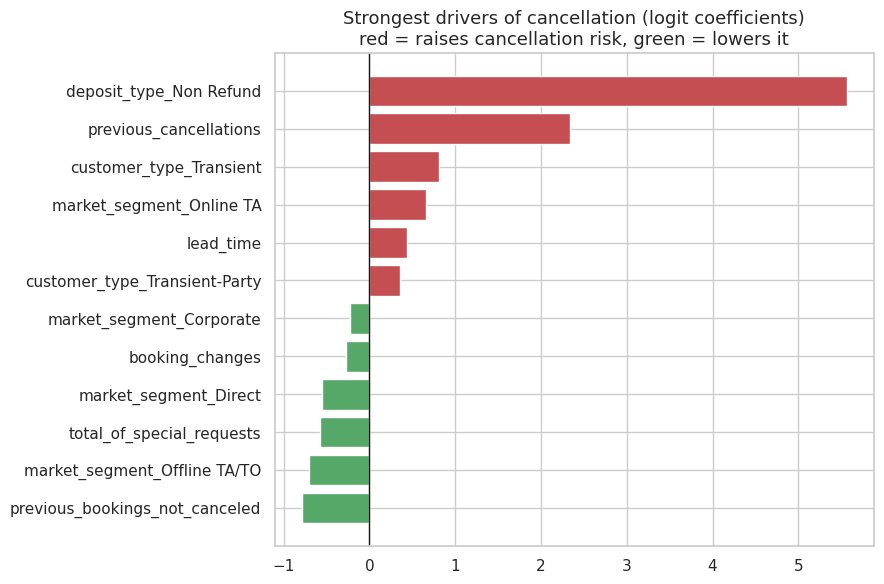

In [ ]:
# Hold-out validation
Xtr, Xte, ytr, yte = train_test_split(Xs, y, test_size=0.25, random_state=42, stratify=y)
clf = LogisticRegression(max_iter=1000).fit(Xtr, ytr)
print(f'Hold-out accuracy: {accuracy_score(yte, clf.predict(Xte)):.3f}')
print(f'Hold-out ROC-AUC : {roc_auc_score(yte, clf.predict_proba(Xte)[:,1]):.3f}')
print(f'Baseline accuracy (always predict majority class): {1 - yte.mean():.3f}')

top = res.reindex(res['coef'].abs().sort_values(ascending=False).index).head(12).sort_values('coef')
colors = ['#c44e52' if c > 0 else '#55a868' for c in top['coef']]
plt.figure(figsize=(9, 6)); plt.barh(top.index, top['coef'], color=colors)
plt.axvline(0, color='k', lw=1); plt.title('Strongest drivers of cancellation (logit coefficients)\nred = raises cancellation risk, green = lowers it')
plt.tight_layout(); plt.show()

**Key findings**
- **Deposit type = Non Refund** has by far the largest effect (odds ratio in the hundreds; ≈99% of these bookings are cancelled). This is counter-intuitive and a known quirk of this dataset (these are largely group/agent bookings that get cancelled), so it flags a data/policy issue to investigate, **not** that non-refundable rates cause cancellations.
- **Previous cancellations** (odds ×10 per +1 SD), **longer lead time** (×1.5), **Transient customers**, **Online TA bookings**, higher **ADR** and longer **stays** all significantly **raise** cancellation risk.
- **Previous bookings not cancelled, special requests (×0.56 per SD), booking changes, repeat guests, Direct and Offline TA/TO bookings** significantly **lower** risk: guests who are engaged or have a good track record rarely cancel.
- **Guests who need a parking space never cancelled** in this data (0 of 7,416), a strong commitment signal.
- **Hotel type:** even after controlling for the other factors, Resort Hotel bookings have ≈17% lower odds of cancellation than City Hotel (OR ≈ 0.83). Part of the raw 14-point gap is explained by lead time, segment and customer mix, but a real City-Hotel effect remains.
- Model quality: pseudo-R² ≈ 0.32, hold-out accuracy ≈ 80% (vs 63% baseline) and ROC-AUC ≈ 0.83, so these factors predict cancellations well.

**Business impact:** Build a cancellation-risk score (lead time, history, engagement) to drive overbooking levels, reminder messages and deposit requirements. Encourage guests to personalise their booking (requests/changes), which is associated with commitment.

### Q22. How does ADR vary with the number of adults, children and babies? (Multiple regression)

In [ ]:
d = df[(df['is_canceled'] == 0)]            # priced, realised stays
Xa = sm.add_constant(d[['adults','children','babies']])
ols = sm.OLS(d['adr'], Xa).fit()
print(ols.summary().tables[1])
print(f"\nR-squared = {ols.rsquared:.3f}  ->  guest counts alone explain only {ols.rsquared:.0%} of ADR variance")

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         39.4452      0.596     66.228      0.000      38.278      40.613
adults        30.8939      0.314     98.444      0.000      30.279      31.509
children      38.4793      0.410     93.892      0.000      37.676      39.283
babies         7.5187      1.417      5.307      0.000       4.742      10.295

R-squared = 0.205  ->  guest counts alone explain only 21% of ADR variance


          Guest counts only  With hotel + season controls
adults               30.890                        25.680
children             38.480                        34.580
babies                7.520                         9.060

R-squared with controls: 0.350


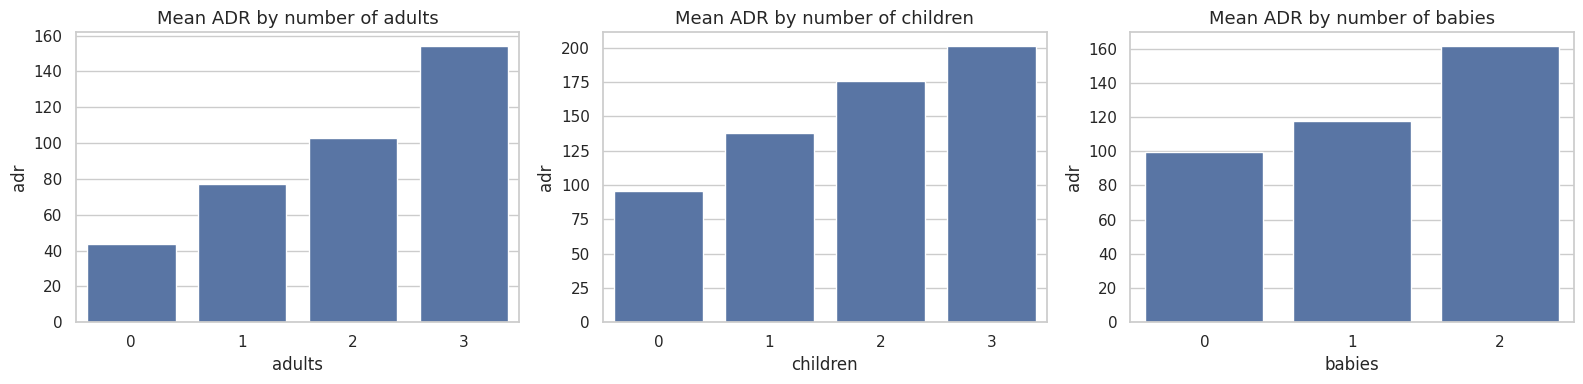

In [ ]:
# Robustness: control for hotel and season (so guest-count effects are not confounded by when/where people stay)
Xc = pd.get_dummies(d[['adults','children','babies','hotel','season']], drop_first=True).astype(float)
ols2 = sm.OLS(d['adr'], sm.add_constant(Xc)).fit()
cmp = pd.DataFrame({'Guest counts only': ols.params, 'With hotel + season controls': ols2.params}).loc[['adults','children','babies']]
print(cmp.round(2)); print(f'\nR-squared with controls: {ols2.rsquared:.3f}')

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ['adults','children','babies']):
    sns.barplot(data=d[d[col] <= 3], x=col, y='adr', errorbar=None, ax=ax); ax.set_title(f'Mean ADR by number of {col}')
plt.tight_layout(); plt.show()

**Key findings**
- **Adults:** each extra adult is associated with about **+€31** ADR (≈ +€26 after controlling for hotel and season); significant.
- **Children:** each extra child is associated with about **+€38** (≈ +€35 with controls), a bigger step than an adult, which suggests families book larger/more expensive rooms or suites.
- **Babies:** a much smaller effect of about **+€8–9**: babies share the room and add little to the rate.
- Guest counts alone explain only **≈21%** of ADR variance (≈35% once hotel and season are added), so season, hotel, room type and market segment matter a lot as well.

**Business impact:** Price per occupancy: standard per-adult supplements, family packages for children, and keep baby supplements low (cots and baby-friendly add-ons can be monetised separately).

### Q23. What is the impact of booking changes on guest satisfaction (special requests)?

Pearson  r = 0.053 (p = 1.3e-74)
Spearman ρ = 0.042 (p = 1.2e-47)
             avg_requests  cancel_rate  bookings
changes_cap                                     
0                   0.556        0.409    101314
1                   0.625        0.142     12700
2                   0.713        0.201      3804
3                   0.810        0.155       927
4+                  0.815        0.180       643


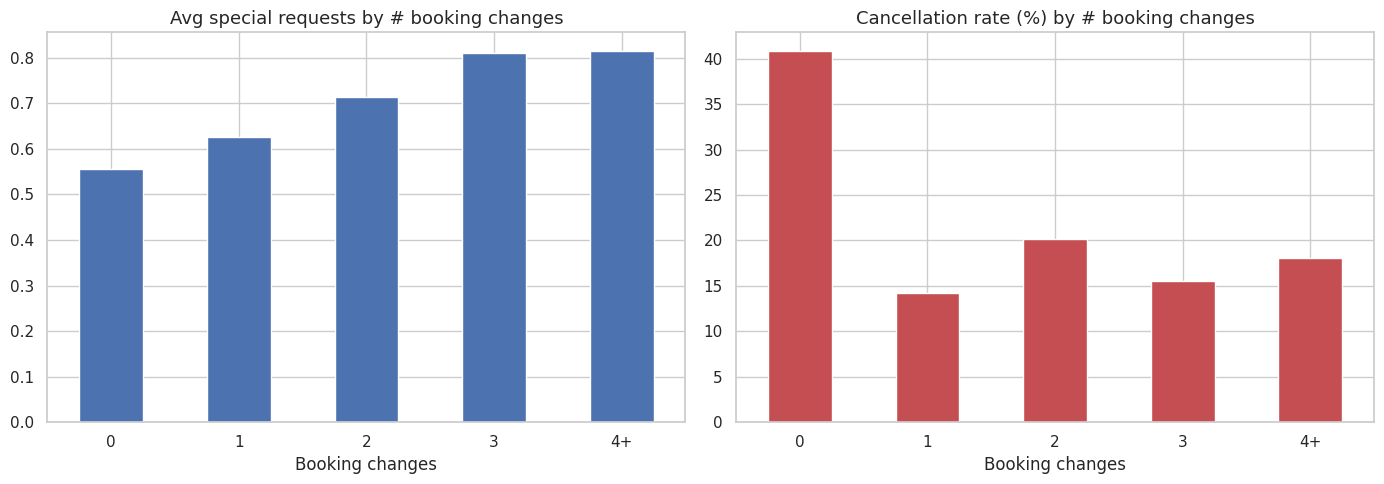

In [ ]:
pear = stats.pearsonr(df['booking_changes'], df['total_of_special_requests'])
spear = stats.spearmanr(df['booking_changes'], df['total_of_special_requests'])
print(f'Pearson  r = {pear[0]:.3f} (p = {pear[1]:.2g})')
print(f'Spearman ρ = {spear[0]:.3f} (p = {spear[1]:.2g})')

g = df.assign(changes_cap=df['booking_changes'].clip(upper=4)).groupby('changes_cap').agg(
        avg_requests=('total_of_special_requests','mean'),
        cancel_rate=('is_canceled','mean'), bookings=('is_canceled','size'))
g.index = g.index.map(lambda x: f'{x}+' if x == 4 else str(x))
print(g.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
g['avg_requests'].plot.bar(ax=axes[0], color='#4c72b0'); axes[0].set_title('Avg special requests by # booking changes'); axes[0].set_xlabel('Booking changes')
(g['cancel_rate']*100).plot.bar(ax=axes[1], color='#c44e52'); axes[1].set_title('Cancellation rate (%) by # booking changes'); axes[1].set_xlabel('Booking changes')
for a in axes: a.tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()

**Insight:** The correlation is **very weak but positive** (r ≈ 0.05). More changes go hand in hand with slightly more requests, but the relationship is not strong. Booking changes are also associated with **lower** cancellation, i.e. guests who modify their booking are committed guests rather than dissatisfied ones.
**Caveat:** The dataset has no satisfaction score, so special requests are only a *proxy* for engagement, not satisfaction.
**Business impact:** Make changes easy and free: flexible modification does not hurt (and probably helps) retention. Capture a real satisfaction metric (post-stay survey/NPS) to answer this question properly.

### Q24. What is the seasonal impact on booking cancellations?

Cancellation rate by month (%):
arrival_date_month
January     30.500
February    33.400
March       32.100
April       40.800
May         39.700
June        41.500
July        37.500
August      37.800
September   39.200
October     38.000
November    31.200
December    35.000

Cancellation rate by season (%):
season
Winter   33.100
Spring   37.800
Summer   38.700
Autumn   36.800


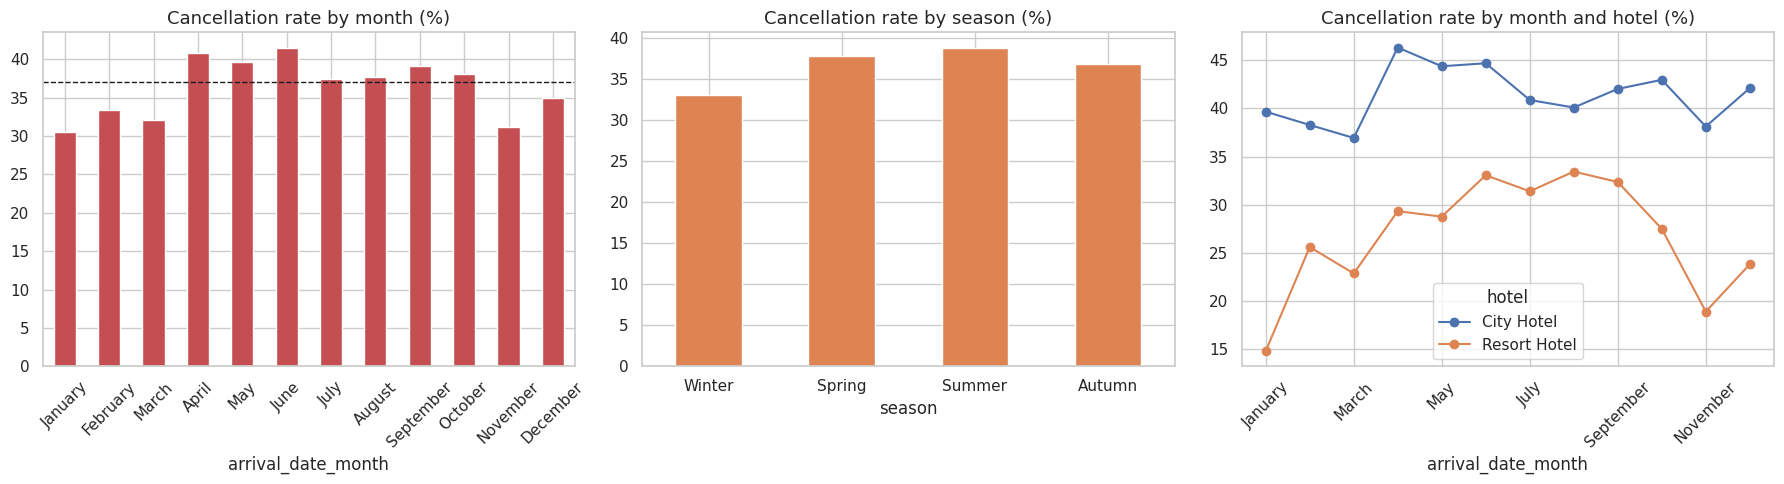

In [ ]:
cm = (df.groupby('arrival_date_month', observed=True)['is_canceled'].mean() * 100).reindex(month_order)
cs = (df.groupby('season')['is_canceled'].mean() * 100).reindex(['Winter','Spring','Summer','Autumn'])
print('Cancellation rate by month (%):'); print(cm.round(1).to_string())
print('\nCancellation rate by season (%):'); print(cs.round(1).to_string())

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
cm.plot.bar(ax=axes[0], color=sns.color_palette('deep')[3]); axes[0].set_title('Cancellation rate by month (%)'); axes[0].axhline(df['is_canceled'].mean()*100, color='k', ls='--', lw=1)
cs.plot.bar(ax=axes[1], color=sns.color_palette('deep')[1]); axes[1].set_title('Cancellation rate by season (%)'); axes[1].tick_params(axis='x', rotation=0)
(df.groupby(['arrival_date_month','hotel'], observed=True)['is_canceled'].mean().unstack().reindex(month_order)*100).plot(ax=axes[2], marker='o'); axes[2].set_title('Cancellation rate by month and hotel (%)')
for a in (axes[0], axes[2]): a.tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()

**Insight:** Cancellations peak in **April–June (≈40–41%)** and are lowest in **January and November (≈30–31%)**, a spread of about 11 percentage points. By season: Summer ≈ 39%, Spring ≈ 38%, Autumn ≈ 37%, Winter ≈ 33%. The busiest months (July, August) do **not** have the highest cancellation rate.
**Business impact:** Plan higher overbooking buffers and stricter policies for Apr–Jun; relax in winter. Use the monthly pattern in revenue forecasting.

### Q25. How does the booking lead-time distribution vary between market segments?

                    count    mean     std   min    25%     50%     75%     max
market_segment                                                                
Groups         19,810.000 187.000 136.800 0.000 70.000 162.000 285.000 629.000
Offline TA/TO  24,218.000 135.000 112.000 0.000 40.000 109.000 201.000 532.000
Online TA      56,477.000  83.000  79.100 0.000 18.000  58.000 129.000 403.000
Direct         12,606.000  49.900  70.100 0.000  1.000  16.000  75.000 737.000
Corporate       5,295.000  22.100  37.400 0.000  2.000   7.000  26.500 343.000
Complementary     743.000  13.300  31.800 0.000  0.000   3.000  11.000 386.000
Aviation          237.000   4.400   4.600 0.000  1.000   3.000   6.000  23.000
Undefined           2.000   1.500   0.700 1.000  1.200   1.500   1.800   2.000


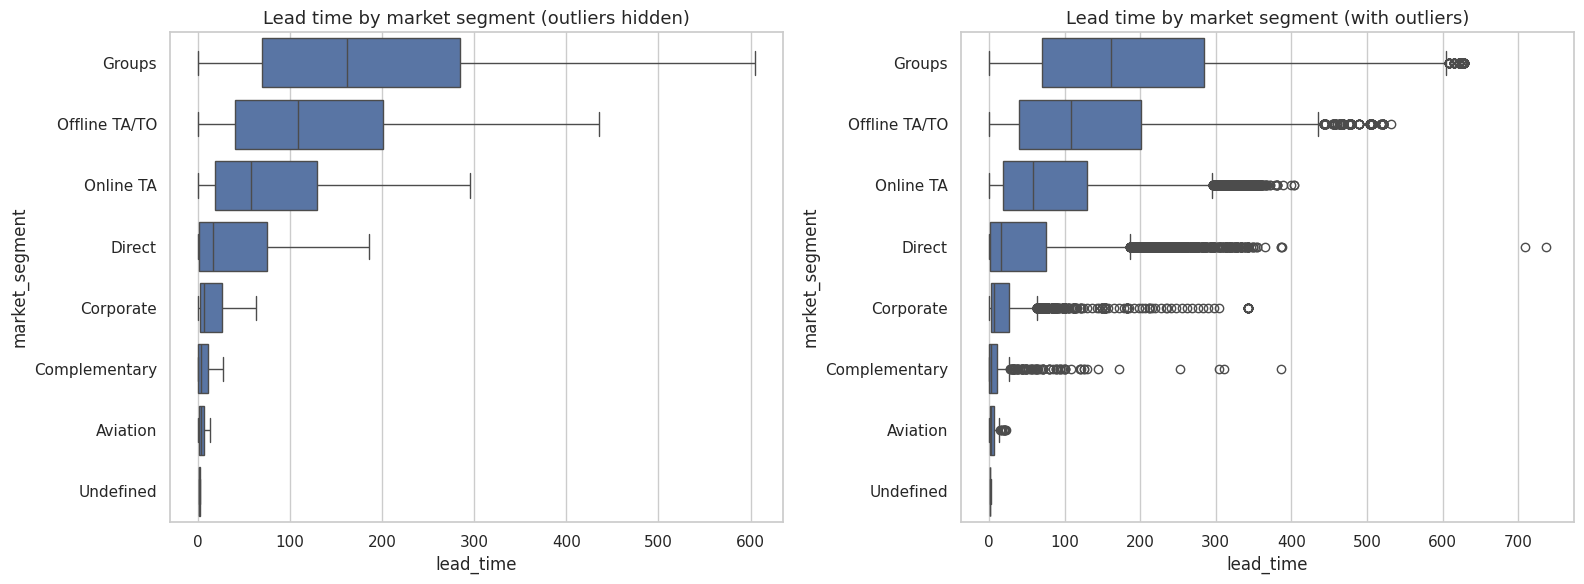

In [ ]:
order = df.groupby('market_segment')['lead_time'].median().sort_values(ascending=False).index
print(df.groupby('market_segment')['lead_time'].describe().loc[order].round(1))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.boxplot(data=df, y='market_segment', x='lead_time', order=order, ax=axes[0], showfliers=False)
axes[0].set_title('Lead time by market segment (outliers hidden)')
sns.boxplot(data=df, y='market_segment', x='lead_time', order=order, ax=axes[1])
axes[1].set_title('Lead time by market segment (with outliers)')
plt.tight_layout(); plt.show()

**Insight:** **Groups** book furthest ahead (median ≈ 5 months), followed by Offline TA/TO (≈ 3.5 months) and Online TA (≈ 2 months). **Direct (≈ 2 weeks), Corporate (≈ 1 week), Complementary and Aviation (a few days)** book much closer to arrival. Within each segment the spread is wide, so averages hide a lot.
**Business impact:** Time promotions by segment: early-bird offers for Groups/Tour operators, last-minute offers for Corporate/Direct. Forecast group demand early because it drives long-lead, high-cancellation business.

## 7️ Final Conclusion

### 7.1 Key findings
- **Volume & mix:** 119k bookings; City Hotel ≈ 66%, Resort ≈ 34%. ~82% come through TA/TO and ~86% involve an agent, so the business depends heavily on intermediaries. Portugal (≈41%) is the main source market, followed by the UK, France, Spain and Germany.
- **Seasonality:** August/July are the peak for bookings, ADR and revenue; Nov–Jan are the troughs. ADR climbed each year (≈ €87 → €98 → €115).
- **Cancellations are the biggest risk:** ~37% of bookings are cancelled (≈ 42% City vs ≈ 28% Resort). Cancellation risk rises with lead time and previous cancellations, and falls for guests who make special requests, change their booking, are repeat guests or have previous non-cancelled stays (and nobody who needed parking cancelled). Risk is highest in Apr–Jun.
- **Guests:** Average stay ≈ 3.4 nights; most guests make no special request; repeat guests are only ~3% and stay for shorter trips.
- **Pricing:** Direct and Online TA segments have the highest ADR; more adults/children raise ADR; special requests have a weak positive link to ADR.

### 7.2 Actionable recommendations
| Area | Recommendation | Owner |
|---|---|---|
| Cancellations | Introduce a **risk score** (lead time, history, engagement). Require deposits / offer non-refundable discounts for long-lead & high-risk bookings; send re-confirmation reminders; set a data-driven **overbooking buffer** (higher at City Hotel and in Apr–Jun) | Management, Ops |
| Marketing | Run campaigns **~3–4 months before peak season**; target PT, UK, FR, ES, DE; early-bird offers for groups, last-minute offers for corporate/direct | Marketing |
| Revenue management | Dynamic pricing with the largest premiums in Jul–Aug (esp. Resort); occupancy-based pricing for adults/children; off-peak packages Nov–Feb | Management |
| Channels | Grow **Direct** (no commission, high ADR) through loyalty benefits and best-rate guarantee; negotiate preferred terms with the top agents | Marketing, Sales |
| Guest experience | Pre-arrival email to capture requests; keep booking changes easy; paid add-ons for high-request guests; run a repeat-guest loyalty scheme that rewards longer stays | Customer Service |
| Operations | Staff and stock for July–August; plan parking mainly for Resort Hotel; keep type-A room inventory protected and manage room reassignments | Operations |

### 7.3 Limitations & areas for further investigation
- **No booking ID / guest ID:** ~27% rows are exact duplicates; they may or may not be real repeat bookings.
- **Only 2 hotels, 2 years (partial 2015 and 2017):** year-on-year comparisons are affected by seasonal mix.
- **No satisfaction score or review data:** special requests are only a proxy for engagement. Add post-stay surveys / NPS.
- **No occupancy / inventory data:** a true occupancy rate and RevPAR cannot be computed.
- **Deposit-type anomaly:** non-refundable bookings show ≈99% cancellation, so investigate how that deposit code is recorded and how group/agent contracts are handled.
- **Next steps:** build a predictive cancellation model (e.g. gradient boosting) for real-time risk scoring; forecast demand with time-series models; analyse agent-level profitability; run A/B tests on deposit and reminder policies.

### 7.4 Ethical & privacy considerations
The data contains guest nationality, family composition and booking history. Any predictive model should be reviewed for **fairness** (e.g. it must not penalise guests purely because of country of origin), data should be **anonymised**, and usage should follow GDPR / applicable data-protection rules.

## 8️ Additional Resources
- Dataset paper: Antonio, Almeida & Nunes (2019), *Hotel booking demand datasets*, Data in Brief — https://www.sciencedirect.com/science/article/pii/S2352340918315191
- Kaggle dataset: https://www.kaggle.com/jessemostipak/hotel-booking-demand
- pandas documentation: https://pandas.pydata.org/docs/
- seaborn gallery: https://seaborn.pydata.org/examples/index.html
- statsmodels logistic regression: https://www.statsmodels.org/stable/generated/statsmodels.discrete.discrete_model.Logit.html
- Hospitality KPIs (ADR, RevPAR, occupancy): STR glossary — https://str.com/data-insights-blog/str-glossary